In [7]:
import numpy as np
import matplotlib.pyplot as plt

# фотонов на МэВ
YIELD = 10000 

import numpy as np
import matplotlib.pyplot as plt

# фотонов на МэВ
YIELD = 10000 

# длина затухания в метрах
L_ATT = 8.0

In [8]:
class PMT:
    def __init__(self, pos, r):
        self.pos = pos
        self.r = r
    
    def n_photoelectrons(self, a):
        return np.random.poisson(a)


class Detector:
    def __init__(self, R, N, r, a):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmts = []
        self._make_pmts()
        
        # кэшируем позиции ФЭУ для быстрого поиска
        self._pmt_positions = np.array([p.pos for p in self.pmts])
    
    def _make_pmts(self):
        i = np.arange(self.N) + 0.5
        phi = np.arccos(1 - 2*i/self.N)
        theta = np.pi * (1 + 5**0.5) * i
        x = self.R * np.sin(phi) * np.cos(theta)
        y = self.R * np.sin(phi) * np.sin(theta)
        z = self.R * np.cos(phi)
        
        for k in range(self.N):
            self.pmts.append(PMT(np.array([x[k], y[k], z[k]]), self.r))
    
    def hit_point(self, origin, direction):
        a = np.dot(direction, direction)
        b = 2 * np.dot(origin, direction)
        c = np.dot(origin, origin) - self.R**2
        
        disc = b**2 - 4*a*c
        if disc < 0:
            return None
        t = (-b + np.sqrt(disc)) / (2*a)
        if t < 0:
            return None
        
        return origin + t * direction
    
    def find_pmt(self, point):
        # векторизованный поиск (из лекции 3)
        dists = np.linalg.norm(self._pmt_positions - point, axis=1)
        idx = np.argmin(dists)
        if dists[idx] <= self.pmts[idx].r:
            return idx
        return -1

In [9]:
class Source:
    def __init__(self, Y=YIELD, L_att=L_ATT):
        self.Y = Y
        self.L_att = L_att
    
    def n_photons(self, E):
        return np.random.poisson(self.Y * E)
    
    def directions(self, N):
        phi = np.random.uniform(0, 2*np.pi, N)
        cos_t = np.random.uniform(-1, 1, N)
        sin_t = np.sqrt(1 - cos_t**2)
        x = sin_t * np.cos(phi)
        y = sin_t * np.sin(phi)
        z = cos_t
        return np.array([x, y, z])
    
    def photon_generator(self, E, batch_size=100):
        N_total = self.n_photons(E)
        
        if N_total == 0:
            return
        
        dirs = self.directions(N_total)
        
        for i in range(0, N_total, batch_size):
            yield dirs[:, i:i+batch_size]

In [10]:
def simulate_event(det, src, E, source_pos=None, attenuation=True):
    if source_pos is None:
        source_pos = np.zeros(3)
    
    total_pe = 0
    gen = src.photon_generator(E)
    
    for batch in gen:
        for i in range(batch.shape[1]):
            d = batch[:, i]
            hit = det.hit_point(source_pos, d)
            if hit is None:
                continue
            
            # если затухание включено, проверяем, долетел ли фотон
            if attenuation:
                dist = np.linalg.norm(hit - source_pos)
                if np.random.uniform(0, 1) > np.exp(-dist / src.L_att):
                    continue
            
            idx = det.find_pmt(hit)
            if idx == -1:
                continue
            
            total_pe += det.pmts[idx].n_photoelectrons(det.a)
            
    return total_pe

In [11]:
det = Detector(R=2.0, N=40, r=0.1, a=0.5)
src = Source()

E_test = 1.0
N_events = 50 # для скорости, если хватит терпения — можно 100

z_positions = np.linspace(-1.5, 1.5, 7)
results_att = []
results_no_att = []

for z in z_positions:
    pos = np.array([0.0, 0.0, z])
    
    # без затухания
    q_no = np.array([simulate_event(det, src, E_test, pos, attenuation=False) 
                     for _ in range(N_events)])
    results_no_att.append(q_no.mean())
    
    # с затуханием
    q_att = np.array([simulate_event(det, src, E_test, pos, attenuation=True) 
                      for _ in range(N_events)])
    results_att.append(q_att.mean())
    
    print(f"z = {z:+.1f} м | без затухания = {results_no_att[-1]:.1f} | с затуханием = {results_att[-1]:.1f}")

z = -1.5 м | без затухания = 121.6 | с затуханием = 99.1
z = -1.0 м | без затухания = 126.2 | с затуханием = 102.4
z = -0.5 м | без затухания = 122.6 | с затуханием = 98.8
z = +0.0 м | без затухания = 122.7 | с затуханием = 98.4
z = +0.5 м | без затухания = 126.0 | с затуханием = 96.0
z = +1.0 м | без затухания = 123.6 | с затуханием = 98.0
z = +1.5 м | без затухания = 121.5 | с затуханием = 102.6


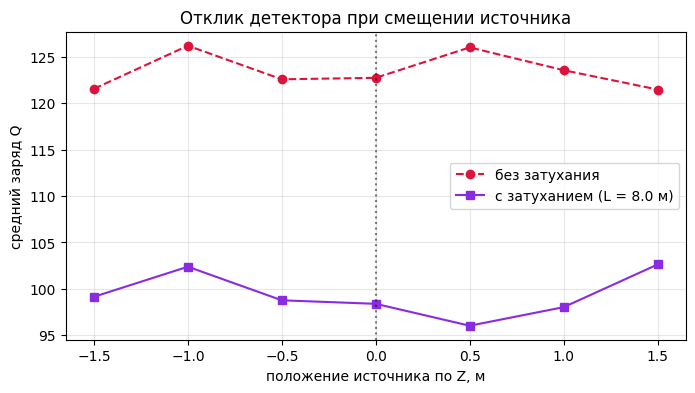

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(z_positions, results_no_att, 'o--', color='crimson', label='без затухания')
plt.plot(z_positions, results_att, 's-', color='blueviolet', label=f'с затуханием (L = {src.L_att} м)')

plt.axvline(0, color='black', linestyle=':', alpha=0.5)

plt.xlabel('положение источника по Z, м')
plt.ylabel('средний заряд Q')
plt.title('Отклик детектора при смещении источника')
plt.legend()
plt.grid(alpha=0.3)
plt.show()